# 01. Data audit (Task Complexity)

**Goal.** Look at the Task Complexity dataset before any model does: what is in it, what is wrong with it, and what that means for the
experiments. Nothing here is fitted or tuned.

**Task.** Predict the Task Complexity score (0-1) of one student in one sprint from five features of the work they were assigned: story points (`SP`), subtask count (`SC`), files involved (`FI`), dependency reach (`DR`, how many files import the changed files, measured before the sprint) and component breadth (`CB`). The label is the rater's `(R_avg - 1) / 4` over the five Task Complexity criteria.

The same five student-disjoint groups and the same 20 rated records are used as for Effort.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"  # tiny data: one thread is faster than OpenMP overhead
sys.path.insert(0, str(Path("../ml_lib").resolve()))
warnings.filterwarnings("ignore")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from core import (GROUPS, SEED, Factor, environment, group_bootstrap, load, log_run, log_signed, make_splits, metrics,
                  paired_diff_bootstrap)
from features import (LABEL_SOURCES, Propagator, design, fit_linear, fit_model, fit_ridge_loo, linear_model, make_model, training_set,
                      transform)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

F = Factor(key="task_complexity", title="Task Complexity", folder=Path(".").resolve(), dataset_file="task_complexity_dataset.csv", label="rater_task_complexity", activity="E_CC")
LABEL, ACT = F.label, F.activity
PROPOSAL = [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log'), ('TC_DR', 'log'), ('TC_CB', 'log')]
VARIANTS = {'proposal 5 (log counts)': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log'), ('TC_DR', 'log'), ('TC_CB', 'log')], 'proposal 5 (raw)': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'raw'), ('TC_DR', 'raw'), ('TC_CB', 'raw')], '4 features (no DR)': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log'), ('TC_CB', 'log')], 'SP, SC, FI': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log')], 'board only (SP, SC)': [('TC_SP', 'raw'), ('TC_SC', 'raw')], 'code only (FI, DR, CB)': [('TC_FI', 'log'), ('TC_DR', 'log'), ('TC_CB', 'log')], 'SP only': [('TC_SP', 'raw')], 'proposal 5 + total points': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log'), ('TC_DR', 'log'), ('TC_CB', 'log'), ('TC_SP_total', 'log')], 'proposal 5 + tasks assigned': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log'), ('TC_DR', 'log'), ('TC_CB', 'log'), ('RF_tasks_assigned', 'raw')]}
FEATURES = ['TC_SP', 'TC_SC', 'TC_FI', 'TC_DR', 'TC_CB']
ZERO_RULE_OK = False
d = load(F)
real = d[d.source == "real"]
syn = d[d.source == "synthetic"]
gold = real[real.label_source == "rater"]
active = real[real[ACT] > 0]
print(F.title, d.shape)

Task Complexity (744, 26)


## 1. Size and structure

In [2]:
sizes = pd.DataFrame({
    "real records": real.groupby("group").size(), "rated (ground truth)": gold.groupby("group").size(),
    "no commits": real[real[ACT] == 0].groupby("group").size(), "students": real.groupby("group").student_id.nunique(),
    "teams": real.groupby("group").team_id.nunique(), "synthetic": syn.groupby("group").size(),
}).fillna(0).astype(int)
sizes.loc["total"] = sizes.sum()
assert (real.groupby("student_id").group.nunique() == 1).all(), "a student appears in more than one group"
print("every student belongs to exactly one group")
sizes

every student belongs to exactly one group


,real records,rated (ground truth),no commits,students,teams,synthetic
group,,,,,,
A,71,7,22,8,6,294
B,28,4,5,5,3,146
C,21,4,5,5,2,66
D,16,3,1,4,2,69
E,8,2,4,4,1,25
total,144,20,37,26,14,600


## 2. Missing, impossible and duplicate values

In [3]:
def share_missing(frame):
    return frame[FEATURES].isna().mean()

miss = pd.DataFrame({"real: share missing": share_missing(real), "synthetic: share missing": share_missing(syn),
                     "rated: missing": gold[FEATURES].isna().sum()})
print("duplicate record ids:", int(d.record_id.duplicated().sum()), "| labels outside 0-1:", int(((d.label < 0) | (d.label > 1)).sum()))
if False:
    print("feature values outside 0-1:", int(((d[FEATURES] < 0) | (d[FEATURES] > 1)).sum().sum()))
miss.round(3)

duplicate record ids: 0 | labels outside 0-1: 0


,real: share missing,synthetic: share missing,rated: missing
TC_SP,0.000,0.000,0
TC_SC,0.000,0.000,0
TC_FI,0.229,0.108,1
TC_DR,0.229,0.108,1
TC_CB,0.229,0.108,1


## 3. Feature distributions

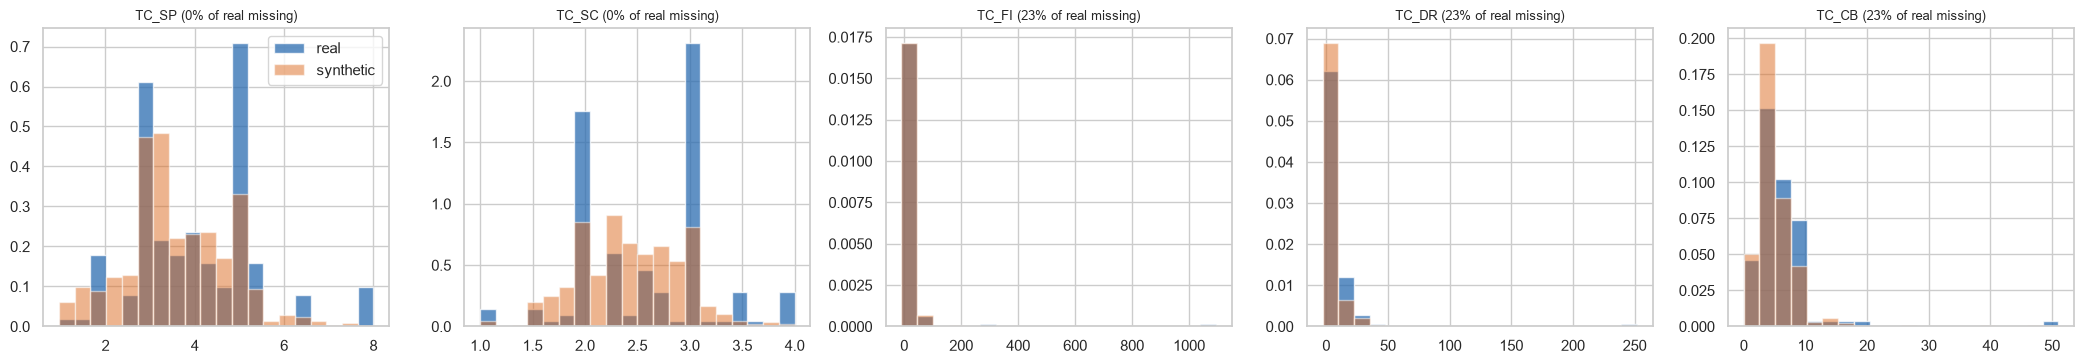

,distinct values,zero share,median,max,skew
feature,,,,,
TC_SP,33,0.00,4.00,8.0,0.65
TC_SC,24,0.00,2.58,4.0,0.04
TC_FI,86,0.01,16.00,1094.0,9.57
TC_DR,40,0.44,2.00,252.0,8.81
TC_CB,50,0.01,5.00,51.0,5.96


In [4]:
fig, axes = plt.subplots(1, len(FEATURES), figsize=(4.2 * len(FEATURES), 3.8))
for a, f in zip(np.atleast_1d(axes), FEATURES):
    x, y = real[f].dropna(), syn[f].dropna()
    bins = np.linspace(min(x.min(), y.min()), max(x.max(), y.max()), 21)
    a.hist(x, bins=bins, color="#2b6cb0", alpha=.75, density=True, label="real")
    a.hist(y, bins=bins, color="#dd6b20", alpha=.5, density=True, label="synthetic")
    a.set_title(f"{f} ({100 * real[f].isna().mean():.0f}% of real missing)", fontsize=9)
np.atleast_1d(axes)[0].legend()
fig.tight_layout()
plt.show()
rows = []
for f in FEATURES:
    x = real[f].dropna()
    rows.append({"feature": f, "distinct values": x.nunique(), "zero share": (x == 0).mean(), "median": x.median(), "max": x.max(), "skew": x.skew()})
pd.DataFrame(rows).set_index("feature").round(2)

## 4. Overlap between features

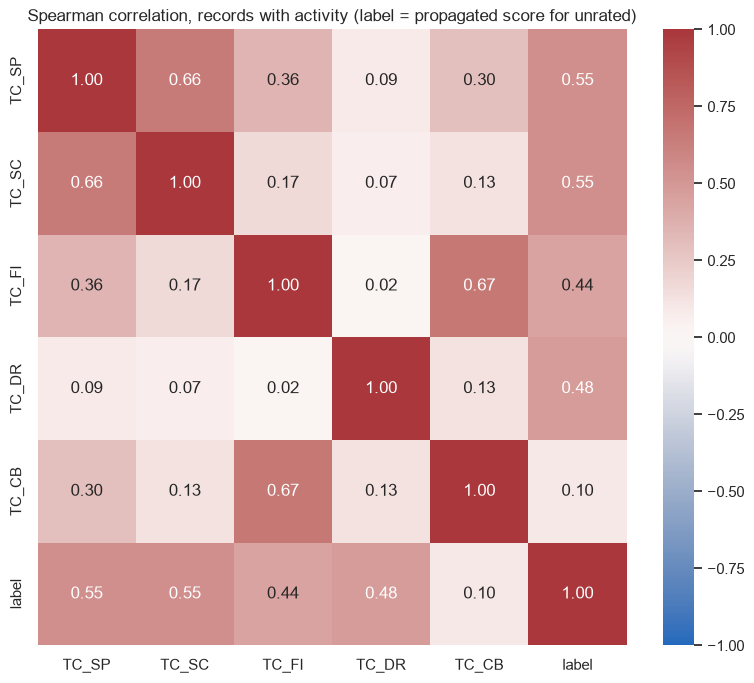

In [5]:
corr = active[FEATURES + ["label"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(1.3 * len(FEATURES) + 3, 1.1 * len(FEATURES) + 2.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation, records with activity (label = propagated score for unrated)")
plt.show()

## 5. The labelled records

count    20.000
mean      0.415
std       0.145
min       0.050
25%       0.337
50%       0.400
75%       0.512
max       0.650
distinct label values: [np.float64(0.05), np.float64(0.3), np.float64(0.35), np.float64(0.4), np.float64(0.45), np.float64(0.5), np.float64(0.55), np.float64(0.6), np.float64(0.65)]


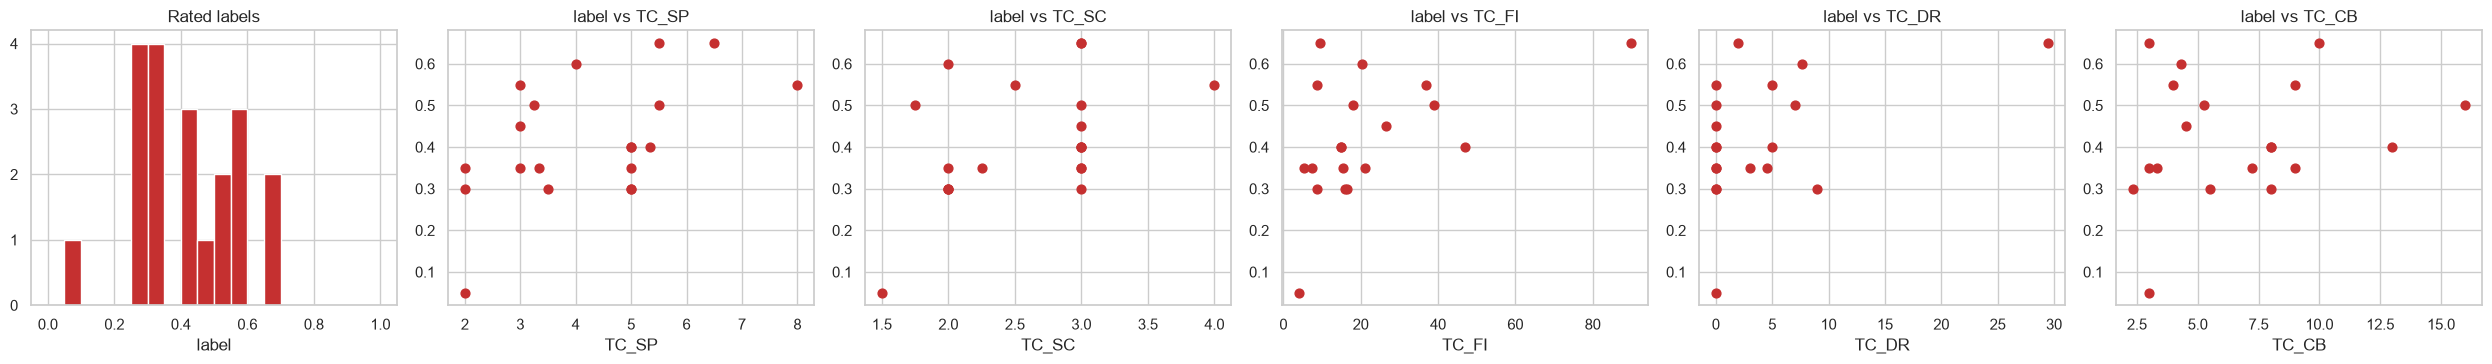

,Spearman with the rated label,rated records with the feature
TC_SP,0.50,20
TC_SC,0.42,20
TC_FI,0.48,19
TC_DR,0.37,19
TC_CB,0.24,19


In [6]:
print(gold[LABEL].describe().round(3).to_string())
print("distinct label values:", sorted(gold[LABEL].round(3).unique()))
fig, axes = plt.subplots(1, len(FEATURES) + 1, figsize=(4.2 * (len(FEATURES) + 1), 3.8))
axes[0].hist(gold[LABEL], bins=np.linspace(0, 1, 21), color="#c53030")
axes[0].set(title="Rated labels", xlabel="label")
for a, f in zip(axes[1:], FEATURES):
    a.scatter(gold[f], gold[LABEL], s=40, color="#c53030")
    a.set(title=f"label vs {f}", xlabel=f)
fig.tight_layout()
plt.show()
rel = pd.DataFrame({"Spearman with the rated label": [gold[[f, LABEL]].dropna().corr(method="spearman").iloc[0, 1] for f in FEATURES],
                    "rated records with the feature": [int(gold[f].notna().sum()) for f in FEATURES]}, index=FEATURES)
rel.round(2)

## 6. Records with no activity

In [7]:
inactive = real[real[ACT] == 0]
print(f"{len(inactive)} of {len(real)} real records ({len(inactive) / len(real):.0%}) have no commits")
print("rated inactive records:", len(gold[gold[ACT] == 0]), "| their labels:", sorted(gold[gold[ACT] == 0][LABEL].round(2).tolist()))
print("what the features show for inactive records:")
inactive[FEATURES].describe().loc[["mean", "min", "max"]].round(2)

37 of 144 real records (26%) have no commits
rated inactive records: 3 | their labels: [0.3, 0.4, 0.55]
what the features show for inactive records:


,TC_SP,TC_SC,TC_FI,TC_DR,TC_CB
mean,4.26,2.35,27.0,0.0,7.75
min,2.00,1.00,0.0,0.0,0.00
max,8.00,4.00,47.0,0.0,13.00


## 7. Team size and synthetic records

In [8]:
print("median of the first feature by team size (active records):")
print(active.groupby("team_size")[FEATURES[0]].median().round(2).to_dict())
print("zero-activity share: real", round((real[ACT] == 0).mean(), 2), "| synthetic", round((syn[ACT] == 0).mean(), 2))
print("synthetic rows whose parents are in different groups:", int((syn.parents_in_group == 0).sum()), "of", len(syn))

median of the first feature by team size (active records):
{3.0: 2.75, 4.0: 4.0, 5.0: 3.6}
zero-activity share: real 0.26 | synthetic 0.12
synthetic rows whose parents are in different groups: 392 of 600


## 8. What this means

| Finding | Consequence |
|---|---|
| 23% of real records (11% of synthetic) have no file, dependency or breadth values, because none of their tasks has linked commits; one rated record is among them | Missing, not zero. Linear models get the training median plus a flag; tree models read the missing value directly |
| `FI`, `DR` and `CB` are very skewed (skew 6-10, max 1,094 files); `DR` is 0 for 44% | Signed log for the linear model |
| Rated labels span only 0.05-0.65, sd 0.145 | A narrow range: always predicting the mean already gives a small error |
| Against the rated label: `SP` 0.50, `FI` 0.48, `SC` 0.42, `DR` 0.37, `CB` 0.24 (Spearman) | Only moderate links; nothing like Effort or Consistency |
| `SP` and `SC` come from the reconstructed Scrum board | Not independent measurements |
| Records with no commits still have complexity values (e.g. mean 27 files) | Complexity is measured from the *tasks assigned*, including ones a teammate finished |
| 392 of 600 synthetic rows have parents in different groups | Excluded from training by the rule in notebook 02 |

Next: **02. Splits and baselines**.